# Baseline and LSFSurfaceIterative sky decomposition

## Table of contents

1. [Objective and comparison contract](#objective-and-comparison-contract)
2. [Mathematical model](#mathematical-model)
3. [Reproducible setup](#reproducible-setup)
4. [Three lunar observing regimes](#three-lunar-observing-regimes)
5. [Standalone baseline example](#standalone-baseline-example)
6. [Standalone LSFSurfaceIterative example](#standalone-lsfsurfaceiterative-example)
7. [Four-way PALACE comparison](#four-way-palace-comparison)
8. [Continuum audit](#continuum-audit)
9. [Observed spectra, models, and residuals](#observed-spectra-models-and-residuals)
10. [Iterative LSF comparison](#iterative-lsf-comparison)
11. [LSF moments and execution time](#lsf-moments-and-execution-time)
12. [Interpretation and reuse contract](#interpretation-and-reuse-contract)
13. [LSF convolution performance validation](#lsf-convolution-performance-validation)
14. [Refinement-cycle sensitivity screen](#refinement-cycle-sensitivity-screen)
15. [Late-cycle convergence and residuals](#late-cycle-convergence-and-residuals)


## Objective and comparison contract

This notebook first gives two explicit decompositions of the same spectrum:
the unchanged `SkyDecomp` baseline and the opt-in
`SkyDecompLSFSurfaceIterative` implementation. It then performs a controlled
two-by-two comparison with two fit implementations and two PALACE bundles:

- `Baseline / PALACE default`;
- `Baseline / PALACE updated`;
- `LSFSurfaceIterative / PALACE default`;
- `LSFSurfaceIterative / PALACE updated`.

All four variants use the same native wavelength grid, selected spectra,
flux scaling, unit inverse variance, and constant input `lsf_sigma`. Within
each method, the PALACE bundle is the only changed input. The updated PALACE
pair is treated as one bundle: this experiment does not separately attribute
changes to the OH and reference-continuum files.

The three spectra are illustrative controlled cases. Metrics and timings are
reported per spectrum and descriptively summarized; they are not a global
ranking or a statistical performance claim.


## Mathematical model

For wavelength pixel $i$, the fitted spectrum is

$$
y_i = C_i(\boldsymbol{\alpha}, K)
      + L_i(\boldsymbol{\beta}, K) + \epsilon_i,
$$

where $C$ contains the Moon/solar-template and the separate `HO2`, `FeO`,
and `O2Ac` continua, $L$ contains OH, atomic, Orc, and O2 emission, and $K$
is the LSF.

`LSFSurfaceIterative` uses one nominal joint seed followed by five complete
cycles by default:

$$
\text{continuum-only} \rightarrow \text{LSF surface}
\rightarrow \text{line-only}.
$$

The continuum spectrum from a continuum stage remains fixed through the
following LSF and line stages. The next cycle re-estimates the continuum.
After the last LSF update, a final continuum-only and line-only pair closes
the model on one final LSF.

A static reference skyline mask $M$ is derived for each iterative fit. At
each continuum stage, weights are recomputed from the current total residual:

$$
w_i^{\rm cont} = {\rm ivar}_i
\begin{cases}
5\times10^{-4}, & i\in M,\\
h_i, & i\notin M,
\end{cases}
$$

where $h_i$ is a channel-wise Huber multiplier with a $3\sigma$ transition.
Positive weights are normalized to mean one within B, R, and Z. LSF and line
stages use the original inverse variance.

For tap $j$, an R/Z kernel surface is

$$K_j(\lambda)=\sum_m B_m(\lambda)c_{jm}.$$

Kernels are nonnegative, normalized, and centrally single-peaked. First-cycle
knot positions are retained exactly in later cycles. Only coefficients,
knots, degrees, channel bounds, tap offsets, configuration, metrics, and
provenance are persistent; full surfaces are reconstructed on demand.

## Reproducible setup

In [1]:
from pathlib import Path
import gc
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from astropy.io import fits
from IPython.display import display
from plotly.subplots import make_subplots


ROOT_CANDIDATES = [
    Path.cwd(),
    Path.cwd() / "skysub",
    Path.cwd() / "lvmsky" / "skysub",
]
ROOT = next(
    path.resolve()
    for path in ROOT_CANDIDATES
    if (path / "sky_decomp" / "fit.py").exists()
)
sys.path.insert(0, str(ROOT))

from sky_decomp.fit import LSF_CHANNELS, SkyDecomp, SkyDecompResult  # noqa: E402
from sky_decomp.lsf_surface_iterative import (  # noqa: E402
    LSFSurfaceIterativeConfig,
    SkyDecompLSFSurfaceIterative,
    apply_lsf_channelwise,
    evaluate_lsf_kernel,
    evaluate_lsf_surface,
    kernel_moments,
)


pio.renderers.default = "plotly_mimetype"
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True})


Matplotlib is building the font cache; this may take a moment.


In [2]:
DATA_PATH = ROOT / "lvmsframe_median_stack_1.2.1_every10.fits"
DEFAULT_BASE_DIR = ROOT
UPDATED_BASE_DIR = (
    ROOT
    / "experiments_joint_diffuse_einstein_jax_v2"
    / "exports"
    / "baseline_compatible"
)
SPECTRUM_ROWS = {
    "Moon below horizon": 1716,
    "Moderate Moon contribution": 837,
    "High Moon contribution": 935,
}
EXAMPLE_REGIME = "Moderate Moon contribution"
FLUX_SCALE = 1.0e14
BASELINE_LSF_REFITS = 3

BASELINE_COMMON_KWARGS = {
    "lsf_sigma": 0.5,
    "moon_smooth_lambda": 0.1,
    "moon_interline_boost": 10000.0,
    "moon_interline_red_min": 6000.0,
    "moon_interline_exclusion_a": 2.5,
    "moon_interline_line_flux_threshold": 0.01,
}
ITERATIVE_COMMON_KWARGS = {
    "lsf_sigma": 0.5,
    "moon_smooth_lambda": 0.1,
    "moon_interline_boost": 0.0,
}
ITERATIVE_CONFIG = LSFSurfaceIterativeConfig()

VARIANT_SPECS = {
    "B-D": {
        "label": "Baseline / PALACE default",
        "method": "Baseline",
        "palace": "default",
        "base_dir": DEFAULT_BASE_DIR,
    },
    "B-U": {
        "label": "Baseline / PALACE updated",
        "method": "Baseline",
        "palace": "updated",
        "base_dir": UPDATED_BASE_DIR,
    },
    "I-D": {
        "label": "LSFSurfaceIterative / PALACE default",
        "method": "LSFSurfaceIterative",
        "palace": "default",
        "base_dir": DEFAULT_BASE_DIR,
    },
    "I-U": {
        "label": "LSFSurfaceIterative / PALACE updated",
        "method": "LSFSurfaceIterative",
        "palace": "updated",
        "base_dir": UPDATED_BASE_DIR,
    },
}
VARIANT_PLOT_ORDER = ("B-D", "B-U", "I-D", "I-U")
VARIANT_STYLES = {
    "B-D": {
        "color": "#2ca02c",
        "dash": "dash",
        "linestyle": "--",
        "width": 1.0,
        "zorder": 2,
    },
    "B-U": {
        "color": "#1f77b4",
        "dash": "dash",
        "linestyle": "--",
        "width": 1.0,
        "zorder": 3,
    },
    "I-D": {
        "color": "#9467bd",
        "dash": "solid",
        "linestyle": "-",
        "width": 1.4,
        "zorder": 4,
    },
    "I-U": {
        "color": "#d62728",
        "dash": "solid",
        "linestyle": "-",
        "width": 1.8,
        "zorder": 5,
    },
}


In [3]:
def show_plotly(figure):
    figure.show(
        config={
            "responsive": True,
            "displaylogo": False,
            "scrollZoom": True,
            "toImageButtonOptions": {"format": "png", "scale": 2},
        }
    )


print(f"Python: {sys.executable}")
print(f"Project root: {ROOT}")
print(f"Input stack: {DATA_PATH.name}")
print("Artifact policy: figures and tables are embedded only in this notebook.")

Python: /opt/homebrew/Caskroom/miniconda/base/envs/lvmdrp_dev_311/bin/python
Project root: /Users/ik52/sci/work/nyuad-galaxies/sdss5/sky_subtract/lvmsky/skysub
Input stack: lvmsframe_median_stack_1.2.1_every10.fits
Artifact policy: figures and tables are embedded only in this notebook.


## Three lunar observing regimes

The rows are fixed for reproducibility. `Moderate Moon contribution` and
`High Moon contribution` are compact labels for these illustrative spectra;
they follow the relative fitted Moon/solar-template components. Moon altitude,
illuminated fraction, and angular separation are observing metadata, not direct
measurements of scattered moonlight. `LSF_SCI` is used only in diagnostics,
not as a fit input.


In [4]:
required_paths = [DATA_PATH, DEFAULT_BASE_DIR, UPDATED_BASE_DIR]
missing_paths = [str(path) for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError("Missing notebook inputs: " + ", ".join(missing_paths))

with fits.open(DATA_PATH, memmap=True) as hdul:
    wave = np.asarray(hdul["WAVE"].data, dtype=float).copy()
    rows = list(SPECTRUM_ROWS.values())
    flux_stack = np.asarray(hdul["FLUX_SCI"].data[rows], dtype=float).copy()
    lsf_stack = np.asarray(hdul["LSF_SCI"].data[rows], dtype=float).copy()
    meta_stack = hdul["META"].data[rows].copy()

spectra = {}
selection_records = []
for index, (label, row) in enumerate(SPECTRUM_ROWS.items()):
    meta = meta_stack[index]
    spectra[label] = {
        "row": row,
        "flux": flux_stack[index] * FLUX_SCALE,
        "ivar": np.ones_like(wave),
        "lsf_fwhm_a": lsf_stack[index],
        "meta": meta,
    }
    selection_records.append(
        {
            "regime": label,
            "row": row,
            "expnum": int(meta["expnum"]),
            "mjd": int(meta["mjd"]),
            "moon_alt_deg": float(meta["moon_alt"]),
            "moon_fli": float(meta["moon_fli"]),
            "science_moon_sep_deg": float(meta["sci_moon_sep"]),
        }
    )

selection_table = pd.DataFrame(selection_records)
display(selection_table.style.format(precision=3))
print(
    f"Native grid: {wave.size} pixels, {wave[0]:.3f}-{wave[-1]:.3f} A; "
    f"flux scale={FLUX_SCALE:.1e}; ivar=ones."
)


def spectrum_plot_label(regime):
    return f"{regime} — expnum {int(spectra[regime]['meta']['expnum'])}"


def build_variant_model(variant):
    spec = VARIANT_SPECS[variant]
    if spec["method"] == "Baseline":
        return SkyDecomp(wave, base_dir=spec["base_dir"], **BASELINE_COMMON_KWARGS)
    return SkyDecompLSFSurfaceIterative(
        wave,
        base_dir=spec["base_dir"],
        config=ITERATIVE_CONFIG,
        **ITERATIVE_COMMON_KWARGS,
    )


for variant in ("B-D", "B-U", "I-D", "I-U"):
    model = build_variant_model(variant)
    del model
gc.collect()
print("Model inputs are ready for the paired comparison.")

,regime,row,expnum,mjd,moon_alt_deg,moon_fli,science_moon_sep_deg
0,Moon below horizon,1716,34935,60730,-22.169,0.176,126.517
1,Moderate Moon contribution,837,32441,60682,22.902,0.509,80.944
2,High Moon contribution,935,13295,60368,63.035,0.880,60.480


Native grid: 12401 pixels, 3600.000-9799.999 A; flux scale=1.0e+14; ivar=ones.


Model inputs are ready for the paired comparison.


## Standalone baseline example

The baseline example below directly constructs `SkyDecomp` and fits the
selected spectrum with the current pipeline setting of three constant-channel
LSF refits. `fit.py` itself is unchanged.

In [5]:
example_spectrum = spectra[EXAMPLE_REGIME]
fit_results = {}
timing_records = []
iterative_masks = {}

t0 = time.perf_counter()
baseline_model = SkyDecomp(
    wave,
    base_dir=DEFAULT_BASE_DIR,
    **BASELINE_COMMON_KWARGS,
)
t1 = time.perf_counter()
baseline_result = baseline_model.fit(
    example_spectrum["flux"],
    example_spectrum["ivar"],
    n_lsf_refits=BASELINE_LSF_REFITS,
)
t2 = time.perf_counter()

fit_results[(EXAMPLE_REGIME, "B-D")] = baseline_result
timing_records.append(
    {
        "regime": EXAMPLE_REGIME,
        "variant": "B-D",
        "variant_label": VARIANT_SPECS["B-D"]["label"],
        "method": "Baseline",
        "palace": "default",
        "run_position": 1,
        "init_wall_s": t1 - t0,
        "fit_wall_s": t2 - t1,
        "total_wall_s": t2 - t0,
        "internal_fit_s": baseline_result.fit_elapsed_sec,
        "fit_status": baseline_result.fit_status,
        "requested_cycles": np.nan,
        "completed_cycles": np.nan,
    }
)
display(pd.DataFrame([timing_records[-1]]).style.format(precision=4))
print(baseline_result.fit_summary)
del baseline_model
gc.collect()

,regime,variant,variant_label,method,palace,run_position,init_wall_s,fit_wall_s,total_wall_s,internal_fit_s,fit_status,requested_cycles,completed_cycles
0,Moderate Moon contribution,B-D,Baseline / PALACE default,Baseline,default,1,13.6985,71.0500,84.7484,71.0478,Solved | md_refit=Solved,nan,nan


status=Solved | md_refit=Solved | npar=442 | ngood=12401 | chi2_red=1.914 | R2=0.89315 | qp_dt=2.92s | moon_smooth_lambda=0.1 | moon_mask_downweight_boost=1e+04 | moon_interline_line_flux_threshold=0.01 | n_lsf_refits=3 | dt=71.05s


118

## Standalone LSFSurfaceIterative example

The same spectrum is now fitted with the iterative method and its public
default of five refinement cycles. The short cell shows the user-facing call;
solver and serialization checks live in the test suite, not in this notebook.

In [6]:
t0 = time.perf_counter()
iterative_model = SkyDecompLSFSurfaceIterative(
    wave,
    base_dir=DEFAULT_BASE_DIR,
    config=ITERATIVE_CONFIG,
    **ITERATIVE_COMMON_KWARGS,
)
t1 = time.perf_counter()
iterative_result = iterative_model.fit(
    example_spectrum["flux"],
    example_spectrum["ivar"],
)
t2 = time.perf_counter()

fit_results[(EXAMPLE_REGIME, "I-D")] = iterative_result
iterative_masks[(EXAMPLE_REGIME, "I-D")] = iterative_model.skyline_mask.copy()
timing_records.append(
    {
        "regime": EXAMPLE_REGIME,
        "variant": "I-D",
        "variant_label": VARIANT_SPECS["I-D"]["label"],
        "method": "LSFSurfaceIterative",
        "palace": "default",
        "run_position": 2,
        "init_wall_s": t1 - t0,
        "fit_wall_s": t2 - t1,
        "total_wall_s": t2 - t0,
        "internal_fit_s": iterative_result.fit_elapsed_sec,
        "fit_status": iterative_result.fit_status,
        "requested_cycles": iterative_result.lsf_state.requested_cycles,
        "completed_cycles": iterative_result.lsf_state.completed_cycles,
    }
)

display(pd.DataFrame([timing_records[-1]]).style.format(precision=4))
print(iterative_result.fit_summary)
del iterative_model
gc.collect()

,regime,variant,variant_label,method,palace,run_position,init_wall_s,fit_wall_s,total_wall_s,internal_fit_s,fit_status,requested_cycles,completed_cycles
0,Moderate Moon contribution,I-D,LSFSurfaceIterative / PALACE default,LSFSurfaceIterative,default,2,6.9169,168.4082,175.3251,168.4063,Solved,5,5


status=Solved | npar=442 | ngood=12401 | chi2_red=1.654 | R2=0.90770 | line_weight=0.0005 | skyline_fraction=0.609 | refinement_cycles=5/5 | fixed_lsf_knots=True | dt=168.41s


118

## Four-way PALACE comparison

The remaining fits complete a paired `method × PALACE bundle` comparison.
Each spectrum/variant uses a fresh model instance. The first two standalone
results above are retained as the corresponding cells of this design, so the
notebook performs 12 fits in total rather than repeating them.

Model-specific skyline masks remain part of each iterative fit. For external
evaluation, each spectrum uses the union of the two iterative masks for all
four variants. This keeps skyline and line-free metrics comparable even when
the updated OH weights change the internal mask.

In [7]:
run_orders = {
    "Moon below horizon": ["I-U", "B-U", "I-D", "B-D"],
    EXAMPLE_REGIME: ["B-D", "I-D", "B-U", "I-U"],
    "High Moon contribution": ["B-U", "B-D", "I-U", "I-D"],
}

for regime, order in run_orders.items():
    spectrum = spectra[regime]
    for run_position, variant in enumerate(order, start=1):
        key = (regime, variant)
        if key in fit_results:
            continue
        spec = VARIANT_SPECS[variant]
        t0 = time.perf_counter()
        model = build_variant_model(variant)
        t1 = time.perf_counter()
        if spec["method"] == "Baseline":
            result = model.fit(
                spectrum["flux"],
                spectrum["ivar"],
                n_lsf_refits=BASELINE_LSF_REFITS,
            )
            requested_cycles = np.nan
            completed_cycles = np.nan
        else:
            result = model.fit(spectrum["flux"], spectrum["ivar"])
            requested_cycles = result.lsf_state.requested_cycles
            completed_cycles = result.lsf_state.completed_cycles
            iterative_masks[key] = model.skyline_mask.copy()
        t2 = time.perf_counter()

        fit_results[key] = result
        timing_records.append(
            {
                "regime": regime,
                "variant": variant,
                "variant_label": spec["label"],
                "method": spec["method"],
                "palace": spec["palace"],
                "run_position": run_position,
                "init_wall_s": t1 - t0,
                "fit_wall_s": t2 - t1,
                "total_wall_s": t2 - t0,
                "internal_fit_s": result.fit_elapsed_sec,
                "fit_status": result.fit_status,
                "requested_cycles": requested_cycles,
                "completed_cycles": completed_cycles,
            }
        )
        del model
        gc.collect()

timing_table = pd.DataFrame(timing_records).sort_values(
    ["regime", "run_position"]
)
timing_summary = (
    timing_table.groupby(["variant", "variant_label"], sort=False)
    .agg(
        n=("total_wall_s", "size"),
        init_median_s=("init_wall_s", "median"),
        fit_median_s=("fit_wall_s", "median"),
        total_median_s=("total_wall_s", "median"),
        total_sum_s=("total_wall_s", "sum"),
    )
    .reset_index()
)
timing_summary = (
    timing_summary.set_index("variant")
    .loc[list(VARIANT_PLOT_ORDER)]
    .reset_index()
)
display(timing_summary.style.format(precision=4))


,variant,variant_label,n,init_median_s,fit_median_s,total_median_s,total_sum_s
0,B-D,Baseline / PALACE default,3,13.6938,73.8636,86.8412,261.1744
1,B-U,Baseline / PALACE updated,3,13.9558,72.4731,86.3060,258.7255
2,I-D,LSFSurfaceIterative / PALACE default,3,13.0569,165.5628,176.5959,531.4214
3,I-U,LSFSurfaceIterative / PALACE updated,3,8.3670,161.6786,169.9721,508.1756


In [8]:
def robust_mad(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return np.nan
    center = np.median(values)
    return 1.4826 * np.median(np.abs(values - center))


def low_frequency_residual(residual, skyline_mask, window=201):
    values = np.asarray(residual, dtype=float).copy()
    values[skyline_mask] = np.nan
    return (
        pd.Series(values)
        .rolling(window, center=True, min_periods=20)
        .median()
        .interpolate(limit_direction="both")
        .to_numpy()
    )


common_masks = {}
mask_records = []
for regime in spectra:
    default_mask = iterative_masks[(regime, "I-D")]
    updated_mask = iterative_masks[(regime, "I-U")]
    union_mask = default_mask | updated_mask
    common_masks[regime] = union_mask
    intersection = default_mask & updated_mask
    mask_records.append(
        {
            "regime": regime,
            "default_fraction": float(np.mean(default_mask)),
            "updated_fraction": float(np.mean(updated_mask)),
            "union_fraction": float(np.mean(union_mask)),
            "jaccard": float(np.sum(intersection) / np.sum(union_mask)),
        }
    )
mask_table = pd.DataFrame(mask_records)

metric_records = []
component_records = []
for regime, spectrum in spectra.items():
    flux = spectrum["flux"]
    skyline_mask = common_masks[regime]
    valid = np.isfinite(flux)
    for variant, spec in VARIANT_SPECS.items():
        result = fit_results[(regime, variant)]
        residual = flux - result.bestfit_lsf
        use = valid & np.isfinite(residual)
        line_free = use & ~skyline_mask
        skyline = use & skyline_mask
        broad = low_frequency_residual(residual, skyline_mask)
        physical_total = (
            result.components["moon"]
            + result.components["diffuse"]
            + result.components["oh"]
            + result.components["atom"]
            + result.components["orc"]
            + result.components["o2"]
        )
        metric_records.append(
            {
                "regime": regime,
                "variant": variant,
                "variant_label": spec["label"],
                "method": spec["method"],
                "palace": spec["palace"],
                "full_rms": float(np.sqrt(np.mean(residual[use] ** 2))),
                "line_free_rms": float(
                    np.sqrt(np.mean(residual[line_free] ** 2))
                ),
                "line_free_mad": float(robust_mad(residual[line_free])),
                "skyline_rms": float(
                    np.sqrt(np.mean(residual[skyline] ** 2))
                ),
                "skyline_mad": float(robust_mad(residual[skyline])),
                "low_frequency_residual_rms": float(
                    np.sqrt(np.mean(broad[line_free] ** 2))
                ),
                "reduced_chi2": result.reduced_chi2,
                "r2": result.r2,
                "fit_status": result.fit_status,
            }
        )
        for component in ("moon", "ho2", "feo", "o2ac"):
            values = result.components[component]
            component_records.append(
                {
                    "regime": regime,
                    "variant": variant,
                    "component": component,
                    "component_rms": float(np.sqrt(np.mean(values**2))),
                    "component_median": float(np.median(values)),
                }
            )

metrics_table = pd.DataFrame(metric_records)
component_table = pd.DataFrame(component_records)
display(mask_table.style.format(precision=4))
display(metrics_table.style.format(precision=5))


,regime,default_fraction,updated_fraction,union_fraction,jaccard
0,Moon below horizon,0.6087,0.5991,0.6186,0.9524
1,Moderate Moon contribution,0.6087,0.5991,0.6186,0.9525
2,High Moon contribution,0.6087,0.5991,0.6186,0.9525


,regime,variant,variant_label,method,palace,full_rms,line_free_rms,line_free_mad,skyline_rms,skyline_mad,low_frequency_residual_rms,reduced_chi2,r2,fit_status
0,Moon below horizon,B-D,Baseline / PALACE default,Baseline,default,1.26264,0.05808,0.03883,1.60475,0.07280,0.01844,1.65318,0.90065,Solved | md_refit=Solved
1,Moon below horizon,B-U,Baseline / PALACE updated,Baseline,updated,0.41100,0.05623,0.03815,0.52070,0.05660,0.01807,0.17517,0.98947,Solved | md_refit=Solved
2,Moon below horizon,I-D,LSFSurfaceIterative / PALACE default,LSFSurfaceIterative,default,1.17315,0.05799,0.03481,1.49092,0.06008,0.01201,1.42715,0.91423,Solved
3,Moon below horizon,I-U,LSFSurfaceIterative / PALACE updated,LSFSurfaceIterative,updated,0.26611,0.05484,0.03343,0.33560,0.03745,0.01085,0.07343,0.99559,Solved
4,Moderate Moon contribution,B-D,Baseline / PALACE default,Baseline,default,1.35868,0.29303,0.13923,1.71211,0.13026,0.05490,1.91423,0.89315,Solved | md_refit=Solved
5,Moderate Moon contribution,B-U,Baseline / PALACE updated,Baseline,updated,0.48524,0.28969,0.12104,0.57349,0.07999,0.03710,0.24416,0.98637,Solved | md_refit=Solved
6,Moderate Moon contribution,I-D,LSFSurfaceIterative / PALACE default,LSFSurfaceIterative,default,1.26281,0.29258,0.12347,1.58909,0.09757,0.04508,1.65362,0.90770,Solved
7,Moderate Moon contribution,I-U,LSFSurfaceIterative / PALACE updated,LSFSurfaceIterative,updated,0.35271,0.28734,0.11668,0.38756,0.05346,0.02887,0.12900,0.99280,Solved
8,High Moon contribution,B-D,Baseline / PALACE default,Baseline,default,1.20864,0.57420,0.28442,1.46910,0.14439,0.11984,1.51480,0.92848,Solved | md_refit=Solved
9,High Moon contribution,B-U,Baseline / PALACE updated,Baseline,updated,0.48414,0.57417,0.27683,0.41910,0.08637,0.10568,0.24306,0.98852,Solved | md_refit=Solved


In [9]:
lower_is_better_metrics = [
    "full_rms",
    "line_free_rms",
    "line_free_mad",
    "skyline_rms",
    "skyline_mad",
    "low_frequency_residual_rms",
]
contrast_specs = {
    "PALACE effect under baseline": ("B-U", "B-D"),
    "PALACE effect under LSFSurfaceIterative": ("I-U", "I-D"),
    "method effect with default PALACE": ("I-D", "B-D"),
    "method effect with updated PALACE": ("I-U", "B-U"),
}
contrast_records = []
for regime in spectra:
    local = metrics_table[metrics_table["regime"] == regime].set_index("variant")
    for metric in lower_is_better_metrics:
        values = local[metric].to_dict()
        for contrast, (new_code, reference_code) in contrast_specs.items():
            reference = values[reference_code]
            contrast_records.append(
                {
                    "regime": regime,
                    "metric": metric,
                    "contrast": contrast,
                    "absolute_change": values[new_code] - reference,
                    "change_percent": (
                        100.0 * (values[new_code] / reference - 1.0)
                        if reference != 0.0
                        else np.nan
                    ),
                }
            )
        interaction = (
            values["I-U"]
            - values["I-D"]
            - values["B-U"]
            + values["B-D"]
        )
        interaction_percent = (
            100.0
            * (
                (values["I-U"] / values["I-D"])
                / (values["B-U"] / values["B-D"])
                - 1.0
            )
            if all(values[code] != 0.0 for code in values)
            else np.nan
        )
        contrast_records.append(
            {
                "regime": regime,
                "metric": metric,
                "contrast": "method × PALACE interaction",
                "absolute_change": interaction,
                "change_percent": interaction_percent,
            }
        )
contrast_table = pd.DataFrame(contrast_records)
contrast_summary = (
    contrast_table.groupby(["metric", "contrast"], sort=False)
    .agg(
        n=("absolute_change", "size"),
        median_absolute_change=("absolute_change", "median"),
        min_absolute_change=("absolute_change", "min"),
        max_absolute_change=("absolute_change", "max"),
        median_change_percent=("change_percent", "median"),
    )
    .reset_index()
)
display(contrast_summary.style.format(precision=4))


,metric,contrast,n,median_absolute_change,min_absolute_change,max_absolute_change,median_change_percent
0,full_rms,PALACE effect under baseline,3,-0.8516,-0.8734,-0.7245,-64.2861
1,full_rms,PALACE effect under LSFSurfaceIterative,3,-0.9070,-0.9101,-0.7110,-72.0696
2,full_rms,method effect with default PALACE,3,-0.0895,-0.0959,-0.0657,-7.0560
3,full_rms,method effect with updated PALACE,3,-0.1325,-0.1449,-0.0522,-27.3122
4,full_rms,method × PALACE interaction,3,-0.0367,-0.0554,0.0135,-21.7939
5,line_free_rms,PALACE effect under baseline,3,-0.0019,-0.0033,-0.0000,-1.1392
6,line_free_rms,PALACE effect under LSFSurfaceIterative,3,-0.0032,-0.0052,-0.0032,-1.7890
7,line_free_rms,method effect with default PALACE,3,-0.0001,-0.0005,0.0375,-0.1420
8,line_free_rms,method effect with updated PALACE,3,-0.0014,-0.0023,0.0343,-0.8103
9,line_free_rms,method × PALACE interaction,3,-0.0019,-0.0032,-0.0013,-0.6573


## Continuum audit

Each panel shows the observed spectrum and the four fitted total continua
(`moon + diffuse`) on one wavelength axis. Baseline variants are dashed green
and blue; iterative variants are solid purple and red. The red
`LSFSurfaceIterative / PALACE updated` curve is drawn last. The `HO2`, `FeO`,
and `O2Ac` contributions remain separate in every result and are tabulated
above; components from the updated iterative result are shown as thin dotted
reference curves.


In [10]:
continuum_figure = make_subplots(
    rows=3,
    cols=1,
    shared_xaxes=True,
    subplot_titles=[
        f"{spectrum_plot_label(label)}: fitted continuum" for label in spectra
    ],
    vertical_spacing=0.08,
)

component_styles = {
    "moon": {"label": "Updated iterative: Moon / solar template", "color": "#a6761d"},
    "ho2": {"label": "Updated iterative: HO2", "color": "#7f8c8d"},
    "feo": {"label": "Updated iterative: FeO", "color": "#9c8c6e"},
    "o2ac": {"label": "Updated iterative: O2Ac", "color": "#6f6f6f"},
}


In [11]:
for row_index, (regime, spectrum) in enumerate(spectra.items(), start=1):
    flux = spectrum["flux"]
    continuum_by_variant = {
        variant: (
            fit_results[(regime, variant)].components["moon"]
            + fit_results[(regime, variant)].components["diffuse"]
        )
        for variant in VARIANT_PLOT_ORDER
    }
    continuum_figure.add_trace(
        go.Scattergl(
            x=wave,
            y=flux,
            mode="lines",
            name="Observed",
            line=dict(color="black", width=0.5),
            opacity=0.3,
            showlegend=row_index == 1,
            legendgroup="Observed",
            legendrank=0,
        ),
        row=row_index,
        col=1,
    )

    reference = fit_results[(regime, "I-U")]
    for component, component_style in component_styles.items():
        continuum_figure.add_trace(
            go.Scattergl(
                x=wave,
                y=reference.components[component],
                mode="lines",
                name=component_style["label"],
                line=dict(
                    color=component_style["color"],
                    dash="dot",
                    width=0.7,
                ),
                opacity=0.7,
                showlegend=row_index == 1,
                legendgroup=f"component-{component}",
                legendrank=20,
            ),
            row=row_index,
            col=1,
        )

    for legend_rank, variant in enumerate(VARIANT_PLOT_ORDER, start=1):
        spec = VARIANT_SPECS[variant]
        style = VARIANT_STYLES[variant]
        continuum_figure.add_trace(
            go.Scattergl(
                x=wave,
                y=continuum_by_variant[variant],
                mode="lines",
                name=spec["label"],
                line=dict(
                    color=style["color"],
                    dash=style["dash"],
                    width=style["width"],
                ),
                showlegend=row_index == 1,
                legendgroup=variant,
                legendrank=legend_rank,
            ),
            row=row_index,
            col=1,
        )

    finite_continua = np.concatenate(list(continuum_by_variant.values()))
    finite_continua = finite_continua[np.isfinite(finite_continua)]
    lower, upper = np.percentile(finite_continua, [0.5, 99.5])
    padding = max(0.05 * (upper - lower), 0.05)
    continuum_figure.update_yaxes(
        range=[lower - padding, upper + padding],
        row=row_index,
        col=1,
    )


In [12]:
continuum_figure.update_layout(
    title="Four-way continuum audit",
    template="plotly_white",
    height=1050,
    hovermode="closest",
    legend=dict(orientation="v", x=1.01, y=1.0),
    margin=dict(t=100, r=320),
)
continuum_figure.update_xaxes(title_text="Wavelength [Angstrom]", row=3)
continuum_figure.update_yaxes(title_text="Flux x 1e14", col=1)
show_plotly(continuum_figure)

## Observed spectra, models, and residuals

Observed spectra are black. The two baseline variants are dashed green and
blue; the two iterative variants are solid purple and red. The red
`LSFSurfaceIterative / PALACE updated` model and shifted residual are drawn
last so they remain visible. Residuals use the matching variant style and are
shifted below the spectrum on the same flux scale. The zero and
$\pm1\sigma$ guides use the common line-free evaluation region.


In [13]:
spectrum_figure = make_subplots(
    rows=3,
    cols=1,
    shared_xaxes=True,
    subplot_titles=[spectrum_plot_label(regime) for regime in spectra],
    vertical_spacing=0.055,
)

for row_index, (regime, spectrum) in enumerate(spectra.items(), start=1):
    flux = spectrum["flux"]
    residuals = {
        variant: flux - fit_results[(regime, variant)].bestfit_lsf
        for variant in VARIANT_PLOT_ORDER
    }
    residual_scale = max(
        float(np.percentile(np.abs(np.concatenate(list(residuals.values()))), 95.0)),
        0.1,
    )
    residual_zero = -4.5 * residual_scale
    sigma = robust_mad(residuals["I-U"][~common_masks[regime]])
    show_legend = row_index == 1

    spectrum_figure.add_trace(
        go.Scattergl(
            x=wave,
            y=flux,
            mode="lines",
            name="Observed",
            line=dict(color="black", width=0.7),
            showlegend=show_legend,
            legendgroup="Observed",
            legendrank=0,
        ),
        row=row_index,
        col=1,
    )

    reference = fit_results[(regime, "I-U")]
    for component, component_style in component_styles.items():
        spectrum_figure.add_trace(
            go.Scattergl(
                x=wave,
                y=reference.components[component],
                mode="lines",
                name=component_style["label"],
                line=dict(
                    color=component_style["color"],
                    dash="dot",
                    width=0.75,
                ),
                opacity=0.7,
                showlegend=show_legend,
                legendgroup=f"component-{component}",
                legendrank=20,
            ),
            row=row_index,
            col=1,
        )
    for guide_rank, (name, level, dash) in enumerate(
        (
            ("Residual zero", residual_zero, "dot"),
            ("+1 common line-free sigma", residual_zero + sigma, "dash"),
            ("-1 common line-free sigma", residual_zero - sigma, "dash"),
        ),
        start=30,
    ):
        spectrum_figure.add_trace(
            go.Scattergl(
                x=wave,
                y=np.full_like(wave, level),
                mode="lines",
                name=name,
                line=dict(color="gray", dash=dash, width=0.7),
                showlegend=show_legend,
                legendgroup=name,
                legendrank=guide_rank,
            ),
            row=row_index,
            col=1,
        )

    for legend_rank, variant in enumerate(VARIANT_PLOT_ORDER, start=1):
        spec = VARIANT_SPECS[variant]
        style = VARIANT_STYLES[variant]
        spectrum_figure.add_trace(
            go.Scattergl(
                x=wave,
                y=fit_results[(regime, variant)].bestfit_lsf,
                mode="lines",
                name=spec["label"],
                line=dict(
                    color=style["color"],
                    dash=style["dash"],
                    width=style["width"],
                ),
                showlegend=show_legend,
                legendgroup=variant,
                legendrank=legend_rank,
            ),
            row=row_index,
            col=1,
        )
        spectrum_figure.add_trace(
            go.Scattergl(
                x=wave,
                y=residual_zero + residuals[variant],
                mode="lines",
                name=f"{spec['label']} residual",
                line=dict(
                    color=style["color"],
                    dash=style["dash"],
                    width=max(style["width"] - 0.15, 0.8),
                ),
                showlegend=False,
                legendgroup=variant,
                hovertemplate=(
                    f"{spec['label']} residual<br>"
                    "Wavelength=%{x:.2f} A<br>Shifted residual=%{y:.5g}<extra></extra>"
                ),
            ),
            row=row_index,
            col=1,
        )


In [14]:
ranges = {
    "Full": [float(wave[0]), float(wave[-1])],
    "[O I] 5577": [5568.0, 5586.0],
    "[O I] 6300/6364": [6288.0, 6374.0],
    "O2 0-1": [8580.0, 8720.0],
    "Red OH": [9300.0, 9450.0],
}
range_buttons = []
for name, bounds in ranges.items():
    updates = {
        f"xaxis{index if index > 1 else ''}.range": bounds
        for index in range(1, 4)
    }
    range_buttons.append(dict(label=name, method="relayout", args=[updates]))

spectrum_figure.update_layout(
    title="Four-way sky decomposition and shifted residuals",
    template="plotly_white",
    height=1150,
    hovermode="closest",
    legend=dict(orientation="v", x=1.01, y=1.0),
    margin=dict(t=150, r=360),
    updatemenus=[
        dict(
            type="buttons",
            direction="right",
            buttons=range_buttons,
            x=0.0,
            xanchor="left",
            y=1.0345,
            yanchor="bottom",
        )
    ],
)
spectrum_figure.update_xaxes(title_text="Wavelength [Angstrom]", row=3)
spectrum_figure.update_yaxes(title_text="Flux x 1e14")
show_plotly(spectrum_figure)

## Iterative LSF comparison

Full LSF surfaces are reconstructed here only for diagnostics. They are not
stored in results or FITS output. For each channel, the left panel shows the
PALACE-default iterative surface, the middle panel shows PALACE updated minus
default, and the right panel compares five 11-tap profile slices. Default
profiles use purple shades; updated profiles use red shades and are drawn
last. B is constant by design; R and Z vary smoothly with wavelength.


In [15]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D


iterative_surfaces = {
    (regime, variant): evaluate_lsf_surface(
        fit_results[(regime, variant)].lsf_state,
        wave,
    )
    for regime in spectra
    for variant in ("I-D", "I-U")
}
first_state = fit_results[(EXAMPLE_REGIME, "I-D")].lsf_state
offsets = np.asarray(first_state.tap_offsets, dtype=float)
channel_bounds = first_state.channel_bounds
slice_colors = plt.cm.coolwarm(np.linspace(0.0, 1.0, 5))
default_profile_colors = plt.cm.Purples(np.linspace(0.45, 0.95, 5))
updated_profile_colors = plt.cm.Reds(np.linspace(0.45, 0.95, 5))
profile_markers = ("o", "s", "^", "D", "P")
turbo_positions = np.linspace(0.0, 1.0, 256)
surface_cmap = LinearSegmentedColormap.from_list(
    "white_to_turbo",
    [(0.0, (1.0, 1.0, 1.0, 1.0))]
    + [
        (0.02 + 0.98 * position, plt.cm.turbo(position))
        for position in turbo_positions
    ],
    N=512,
)


def channel_mask(lower, upper):
    use = np.ones(wave.size, dtype=bool)
    if lower is not None:
        use &= wave >= lower
    if upper is not None:
        use &= wave < upper
    return use


surface_max = max(float(np.max(surface)) for surface in iterative_surfaces.values())
difference_max = max(
    float(
        np.max(
            np.abs(
                iterative_surfaces[(regime, "I-U")]
                - iterative_surfaces[(regime, "I-D")]
            )
        )
    )
    for regime in spectra
)
difference_max = max(difference_max, 1.0e-8)


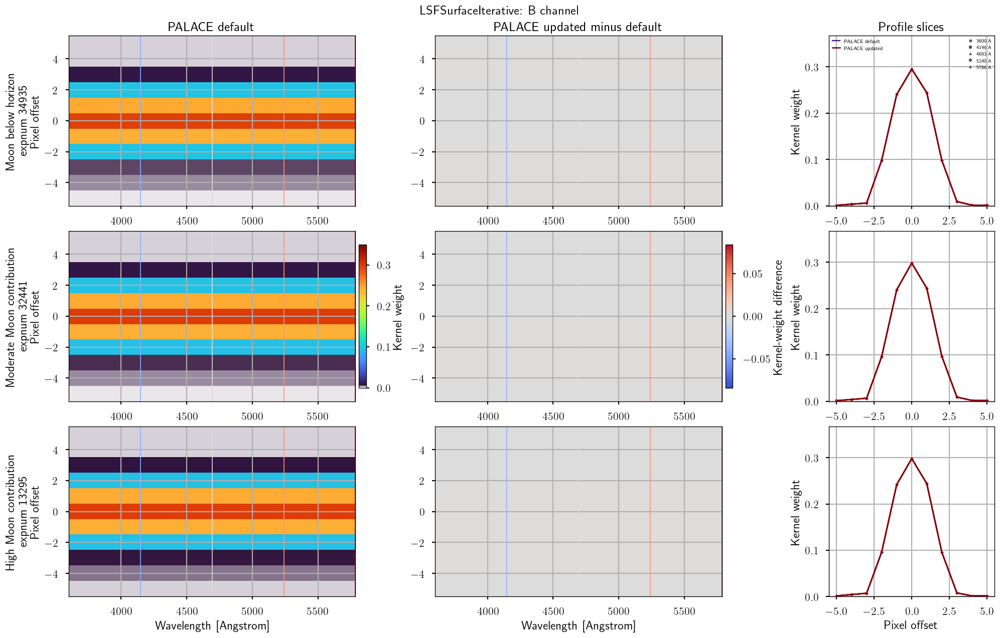

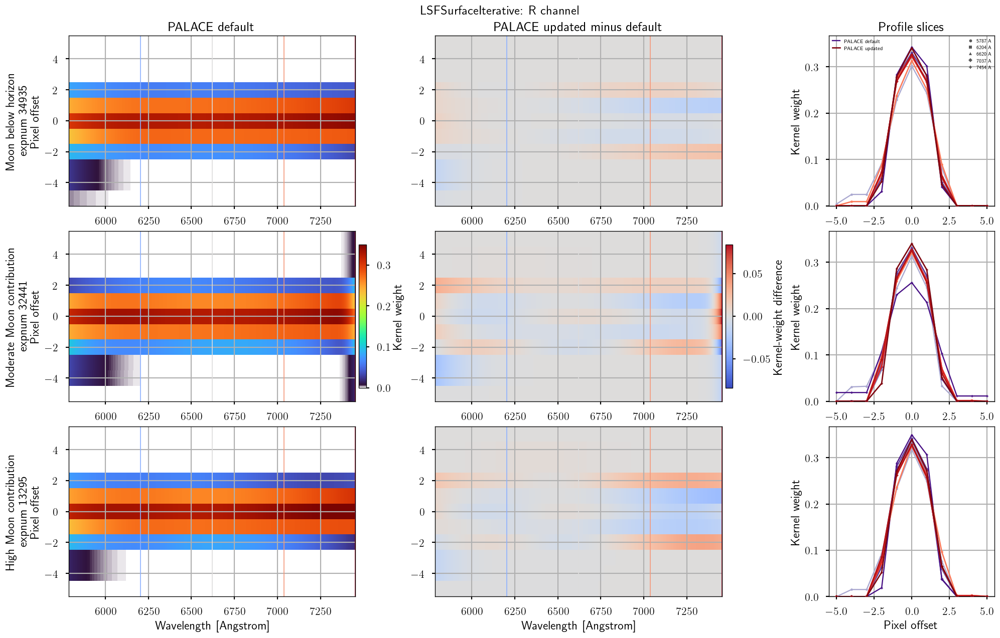

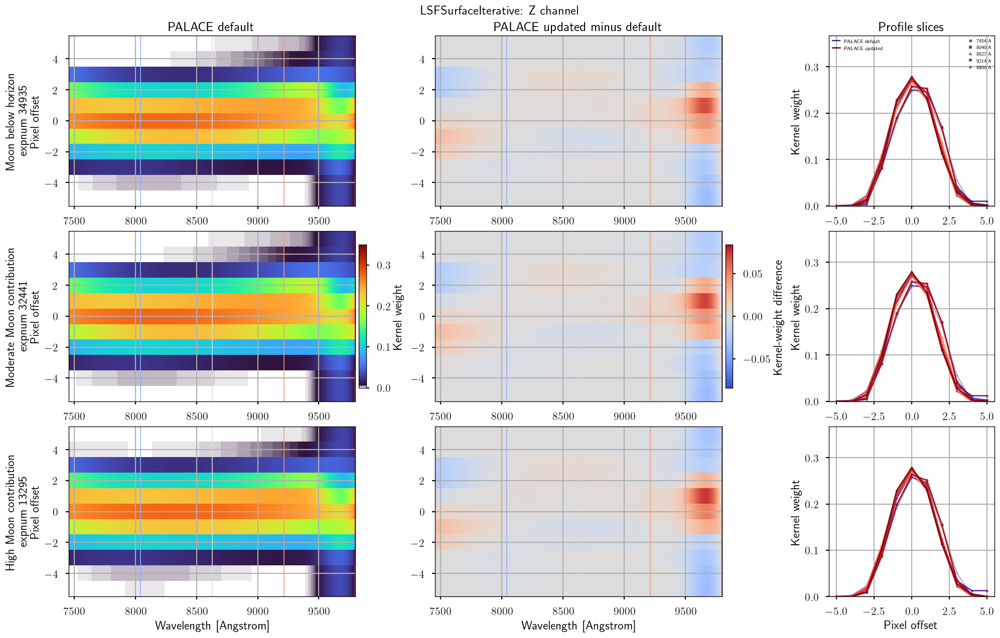

In [16]:
for channel in ("B", "R", "Z"):
    indices = np.flatnonzero(channel_mask(*channel_bounds[channel]))
    channel_wave = wave[indices]
    slice_positions = np.rint(np.linspace(0, indices.size - 1, 5)).astype(int)
    slice_indices = indices[slice_positions]

    figure, axes = plt.subplots(
        nrows=len(spectra),
        ncols=3,
        figsize=(16.5, 10.5),
        squeeze=False,
        gridspec_kw={"width_ratios": [2.6, 2.6, 1.5]},
        constrained_layout=True,
    )
    default_image = None
    difference_image = None
    for row_index, regime in enumerate(spectra):
        default_surface = iterative_surfaces[(regime, "I-D")]
        updated_surface = iterative_surfaces[(regime, "I-U")]
        local_default = default_surface[indices]
        local_difference = updated_surface[indices] - local_default

        default_image = axes[row_index, 0].imshow(
            local_default.T,
            origin="lower",
            aspect="auto",
            interpolation="nearest",
            extent=(
                channel_wave[0],
                channel_wave[-1],
                offsets[0] - 0.5,
                offsets[-1] + 0.5,
            ),
            cmap=surface_cmap,
            vmin=0.0,
            vmax=surface_max,
        )
        difference_image = axes[row_index, 1].imshow(
            local_difference.T,
            origin="lower",
            aspect="auto",
            interpolation="nearest",
            extent=(
                channel_wave[0],
                channel_wave[-1],
                offsets[0] - 0.5,
                offsets[-1] + 0.5,
            ),
            cmap="coolwarm",
            vmin=-difference_max,
            vmax=difference_max,
        )
        for slice_index, color in zip(slice_indices, slice_colors):
            axes[row_index, 0].axvline(wave[slice_index], color=color, linewidth=1)
            axes[row_index, 1].axvline(wave[slice_index], color=color, linewidth=1)
        for slice_index, color, marker in zip(
            slice_indices,
            default_profile_colors,
            profile_markers,
        ):
            axes[row_index, 2].plot(
                offsets,
                default_surface[slice_index],
                color=color,
                linestyle="-",
                linewidth=1.4,
                marker=marker,
                markersize=2.8,
                zorder=3,
                label="_nolegend_",
            )
        for slice_index, color, marker in zip(
            slice_indices,
            updated_profile_colors,
            profile_markers,
        ):
            axes[row_index, 2].plot(
                offsets,
                updated_surface[slice_index],
                color=color,
                linestyle="-",
                linewidth=1.6,
                marker=marker,
                markersize=2.8,
                zorder=4,
                label="_nolegend_",
            )
        expnum = int(spectra[regime]["meta"]["expnum"])
        axes[row_index, 0].set_ylabel(
            f"{regime}\nexpnum {expnum}\nPixel offset"
        )
        axes[row_index, 2].set_ylabel("Kernel weight")
        axes[row_index, 2].set_ylim(0.0, 1.05 * surface_max)
        if row_index == 0:
            axes[row_index, 0].set_title("PALACE default")
            axes[row_index, 1].set_title("PALACE updated minus default")
            axes[row_index, 2].set_title("Profile slices")
            model_legend = axes[row_index, 2].legend(
                handles=[
                    Line2D(
                        [0],
                        [0],
                        color=default_profile_colors[-1],
                        linewidth=1.4,
                        label="PALACE default",
                    ),
                    Line2D(
                        [0],
                        [0],
                        color=updated_profile_colors[-1],
                        linewidth=1.6,
                        label="PALACE updated",
                    ),
                ],
                loc="upper left",
                fontsize=6.0,
                frameon=False,
                handlelength=1.5,
                borderaxespad=0.25,
            )
            axes[row_index, 2].add_artist(model_legend)
            axes[row_index, 2].legend(
                handles=[
                    Line2D(
                        [0],
                        [0],
                        color="0.35",
                        marker=marker,
                        linestyle="None",
                        markersize=3.5,
                        label=f"{wave[slice_index]:.0f} A",
                    )
                    for slice_index, marker in zip(slice_indices, profile_markers)
                ],
                loc="upper right",
                fontsize=5.7,
                frameon=False,
                handlelength=0.8,
                borderaxespad=0.25,
            )
        if row_index == len(spectra) - 1:
            axes[row_index, 0].set_xlabel("Wavelength [Angstrom]")
            axes[row_index, 1].set_xlabel("Wavelength [Angstrom]")
            axes[row_index, 2].set_xlabel("Pixel offset")

    figure.suptitle(f"LSFSurfaceIterative: {channel} channel", fontsize=15)
    figure.colorbar(
        default_image,
        ax=axes[:, 0].tolist(),
        fraction=0.025,
        pad=0.012,
        label="Kernel weight",
    )
    figure.colorbar(
        difference_image,
        ax=axes[:, 1].tolist(),
        fraction=0.025,
        pad=0.012,
        label="Kernel-weight difference",
    )
    plt.show()


## LSF moments and execution time

Centroid and Gaussian-equivalent FWHM are descriptive summaries of each
reconstructed iterative surface. The full kernel remains authoritative. The
moment figure separates the three exposures into columns and identifies each
one by `expnum`. Execution time is measured externally with
`time.perf_counter`: constructor, fit, and total are reported separately. This
is same-session warm-cache timing, not a cold-start or statistically repeated
benchmark.


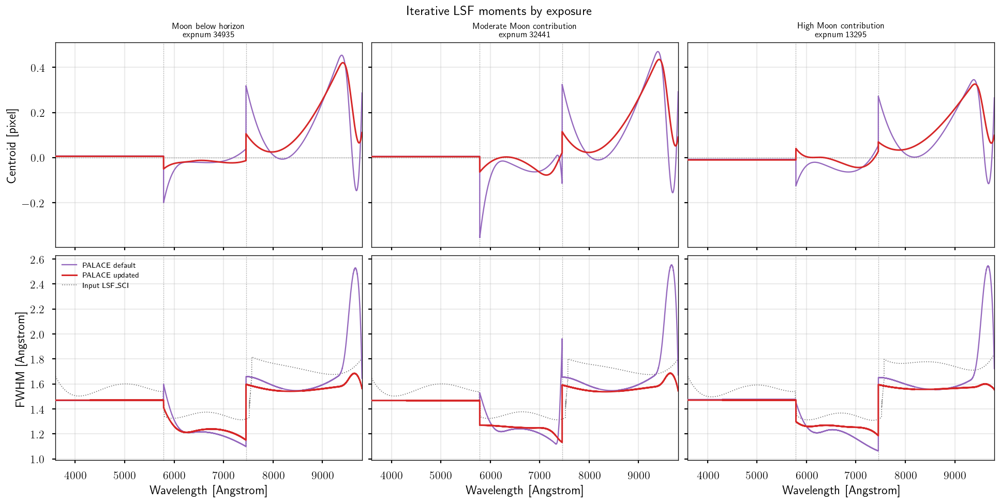

In [17]:
from matplotlib.lines import Line2D


fwhm_from_sigma = 2.0 * np.sqrt(2.0 * np.log(2.0))
pixel_scale_a = np.abs(np.gradient(wave))

moment_figure, moment_axes = plt.subplots(
    nrows=2,
    ncols=len(spectra),
    figsize=(16, 8),
    sharex="col",
    sharey="row",
    constrained_layout=True,
)
moment_records = []
sensitivity_records = []
for column_index, (regime, spectrum) in enumerate(spectra.items()):
    center_axis = moment_axes[0, column_index]
    width_axis = moment_axes[1, column_index]
    center_axis.axhline(
        0.0,
        color="0.45",
        linewidth=0.8,
        linestyle=":",
        zorder=0,
    )
    for boundary in (5787.0, 7454.0):
        center_axis.axvline(
            boundary,
            color="0.55",
            linewidth=0.8,
            linestyle=":",
            zorder=0,
        )
        width_axis.axvline(
            boundary,
            color="0.55",
            linewidth=0.8,
            linestyle=":",
            zorder=0,
        )

    width_axis.plot(
        wave,
        np.asarray(spectrum["lsf_fwhm_a"], dtype=float),
        color="0.45",
        linestyle=":",
        linewidth=1.0,
        zorder=1,
        label="Input LSF_SCI",
    )

    centers = {}
    widths = {}
    for variant in ("I-D", "I-U"):
        surface = iterative_surfaces[(regime, variant)]
        center, sigma = kernel_moments(surface)
        fitted_fwhm_a = fwhm_from_sigma * sigma * pixel_scale_a
        centers[variant] = center
        widths[variant] = fitted_fwhm_a
        style = VARIANT_STYLES[variant]
        palace_label = VARIANT_SPECS[variant]["palace"]
        center_axis.plot(
            wave,
            center,
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=style["width"],
            zorder=style["zorder"],
            label=f"PALACE {palace_label}",
        )
        width_axis.plot(
            wave,
            fitted_fwhm_a,
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=style["width"],
            zorder=style["zorder"],
            label=f"PALACE {palace_label}",
        )
        for channel, lower, upper in LSF_CHANNELS:
            use = channel_mask(lower, upper)
            metric = fit_results[(regime, variant)].lsf_state.metrics[channel]
            moment_records.append(
                {
                    "regime": regime,
                    "palace": palace_label,
                    "channel": channel,
                    "lsf_status": metric["status"],
                    "center_median_pix": float(np.median(center[use])),
                    "center_min_pix": float(np.min(center[use])),
                    "center_max_pix": float(np.max(center[use])),
                    "fwhm_median_a": float(np.median(fitted_fwhm_a[use])),
                }
            )

    for channel, lower, upper in LSF_CHANNELS:
        use = channel_mask(lower, upper)
        surface_difference = (
            iterative_surfaces[(regime, "I-U")][use]
            - iterative_surfaces[(regime, "I-D")][use]
        )
        sensitivity_records.append(
            {
                "regime": regime,
                "channel": channel,
                "median_abs_kernel_difference": float(
                    np.median(np.abs(surface_difference))
                ),
                "max_abs_kernel_difference": float(
                    np.max(np.abs(surface_difference))
                ),
                "median_centroid_change_pix": float(
                    np.median(centers["I-U"][use] - centers["I-D"][use])
                ),
                "median_fwhm_change_a": float(
                    np.median(widths["I-U"][use] - widths["I-D"][use])
                ),
            }
        )

    expnum = int(spectrum["meta"]["expnum"])
    center_axis.set_title(f"{regime}\nexpnum {expnum}", fontsize=10)
    width_axis.set_xlabel("Wavelength [Angstrom]")
    for axis in (center_axis, width_axis):
        axis.set_xlim(wave[0], wave[-1])
        axis.grid(alpha=0.25)

moment_axes[0, 0].set_ylabel("Centroid [pixel]")
moment_axes[1, 0].set_ylabel("FWHM [Angstrom]")
moment_legend_handles = [
    Line2D(
        [0],
        [0],
        color=VARIANT_STYLES["I-D"]["color"],
        linewidth=VARIANT_STYLES["I-D"]["width"],
        label="PALACE default",
    ),
    Line2D(
        [0],
        [0],
        color=VARIANT_STYLES["I-U"]["color"],
        linewidth=VARIANT_STYLES["I-U"]["width"],
        label="PALACE updated",
    ),
    Line2D(
        [0],
        [0],
        color="0.45",
        linestyle=":",
        linewidth=1.0,
        label="Input LSF_SCI",
    ),
]
moment_axes[1, 0].legend(
    handles=moment_legend_handles,
    loc="upper left",
    fontsize=8.5,
    frameon=False,
)
moment_figure.suptitle("Iterative LSF moments by exposure", fontsize=15)
plt.show()


In [18]:
display(pd.DataFrame(moment_records).style.format(precision=5))
display(pd.DataFrame(sensitivity_records).style.format(precision=6))
display(timing_summary.style.format(precision=4))


,regime,palace,channel,lsf_status,center_median_pix,center_min_pix,center_max_pix,fwhm_median_a
0,Moon below horizon,default,B,Solved,0.00749,0.00749,0.00749,1.46752
1,Moon below horizon,default,R,Solved,-0.02042,-0.19901,0.03867,1.21138
2,Moon below horizon,default,Z,Solved,0.10787,-0.14619,0.45392,1.60597
3,Moon below horizon,updated,B,Solved,0.00590,0.00590,0.00590,1.47040
4,Moon below horizon,updated,R,Solved,-0.01949,-0.04982,-0.01198,1.22932
5,Moon below horizon,updated,Z,Solved,0.10070,0.02518,0.42080,1.56183
6,Moderate Moon contribution,default,B,Solved,0.00569,0.00569,0.00569,1.46828
7,Moderate Moon contribution,default,R,Solved,-0.04629,-0.35459,0.01086,1.23132
8,Moderate Moon contribution,default,Z,Solved,0.10965,-0.15545,0.47007,1.60573
9,Moderate Moon contribution,updated,B,Solved,0.00445,0.00445,0.00445,1.46786


,regime,channel,median_abs_kernel_difference,max_abs_kernel_difference,median_centroid_change_pix,median_fwhm_change_a
0,Moon below horizon,B,0.000113,0.000186,-0.001597,0.002877
1,Moon below horizon,R,0.000353,0.021938,0.003956,0.021340
2,Moon below horizon,Z,0.002491,0.068938,0.019637,-0.045647
3,Moderate Moon contribution,B,0.000032,0.000091,-0.001242,-0.000421
4,Moderate Moon contribution,R,0.001507,0.084197,0.024512,0.021964
5,Moderate Moon contribution,Z,0.002438,0.071664,0.018060,-0.048034
6,High Moon contribution,B,0.000127,0.000221,-0.002862,-0.004915
7,High Moon contribution,R,0.001492,0.037660,0.027814,0.050265
8,High Moon contribution,Z,0.002376,0.075361,0.025891,-0.035526


,variant,variant_label,n,init_median_s,fit_median_s,total_median_s,total_sum_s
0,B-D,Baseline / PALACE default,3,13.6938,73.8636,86.8412,261.1744
1,B-U,Baseline / PALACE updated,3,13.9558,72.4731,86.3060,258.7255
2,I-D,LSFSurfaceIterative / PALACE default,3,13.0569,165.5628,176.5959,531.4214
3,I-U,LSFSurfaceIterative / PALACE updated,3,8.3670,161.6786,169.9721,508.1756


In [19]:
runtime_figure = go.Figure()
for column, label in (
    ("init_median_s", "Median constructor"),
    ("fit_median_s", "Median fit"),
    ("total_median_s", "Median total"),
):
    runtime_figure.add_trace(
        go.Bar(
            x=timing_summary["variant_label"],
            y=timing_summary[column],
            name=label,
        )
    )
timing_expnums = ", ".join(
    str(int(spectrum["meta"]["expnum"])) for spectrum in spectra.values()
)
runtime_figure.update_layout(
    title=f"Same-session warm-cache medians over expnums {timing_expnums}",
    template="plotly_white",
    barmode="group",
    xaxis_title="Variant",
    yaxis_title="Wall time [s]",
    height=650,
    hovermode="closest",
    legend=dict(orientation="h", y=1.08),
    margin=dict(b=170),
)
runtime_figure.update_xaxes(tickangle=-20)
show_plotly(runtime_figure)

## Interpretation and reuse contract

The displayed four-way comparison separates the bundled PALACE effect within
each method, the method effect within each PALACE bundle, and their
interaction. Negative changes in the reported RMS/MAD contrasts mean lower
residuals. Improvements are claimed only for the exact displayed spectrum
and metric; mixed changes remain visible.

Use `SkyDecompLSFSurfaceIterative` with one
`LSFSurfaceIterativeConfig`. The default `n_refinement_cycles=5` is configurable. `LSFSurfaceIterativeResult` preserves every
`SkyDecompResult` field and adds only compact `lsf_state`. Runtime-only
diagnostics such as the current full surface, skyline mask, continuum
weights, and per-stage records remain on the fitted model instance.

`evaluate_lsf_kernel(state, wavelength)` evaluates one 11-tap kernel;
`evaluate_lsf_surface(state, wave)` creates a surface on demand; and
`apply_lsf_channelwise(state, wave, values)` applies it without crossing B/R/Z
boundaries. Production FITS output appends only `LSF_COEF`, `LSF_KNOTS`, and
`LSF_META`. No wavelength array or full surface is persisted.

This notebook writes no figures, HTML, CSV, NPZ, FITS, or other result files.
All tables and figures are embedded as notebook outputs.

In [20]:
interpretation_rows = []
for regime in spectra:
    local = contrast_table[
        (contrast_table["regime"] == regime)
        & contrast_table["metric"].isin(
            ["full_rms", "line_free_rms", "skyline_rms"]
        )
    ]
    for _, row in local.iterrows():
        interpretation_rows.append(
            {
                "regime": regime,
                "metric": row["metric"],
                "contrast": row["contrast"],
                "change_percent": row["change_percent"],
            }
        )

display(pd.DataFrame(interpretation_rows).style.format(precision=3))
print(
    "CLI default: python decompose_parallel.py DATA_FILE PALACE_DIR "
    "--fit-model lsf-surface-iterative"
)

,regime,metric,contrast,change_percent
0,Moon below horizon,full_rms,PALACE effect under baseline,-67.449
1,Moon below horizon,full_rms,PALACE effect under LSFSurfaceIterative,-77.316
2,Moon below horizon,full_rms,method effect with default PALACE,-7.087
3,Moon below horizon,full_rms,method effect with updated PALACE,-35.252
4,Moon below horizon,full_rms,method × PALACE interaction,-30.313
5,Moon below horizon,line_free_rms,PALACE effect under baseline,-3.188
6,Moon below horizon,line_free_rms,PALACE effect under LSFSurfaceIterative,-5.437
7,Moon below horizon,line_free_rms,method effect with default PALACE,-0.142
8,Moon below horizon,line_free_rms,method effect with updated PALACE,-2.461
9,Moon below horizon,line_free_rms,method × PALACE interaction,-2.323


CLI default: python decompose_parallel.py DATA_FILE PALACE_DIR --fit-model lsf-surface-iterative


## Performance research: N=4 history and N=5 follow-up

The first round replaced indexed LSF convolution with contiguous slices. On
the controlled N=4 spectrum it produced a bitwise-identical result and a
1.16x median speedup; that optimization is now the production baseline.

The new round profiles the public N=5 workload: native 12,401-pixel row 837,
flux scaled by $10^{14}$, unit inverse variance, and default PALACE. Timings
come from seven interleaved full fits after warm-up. Candidate implementations
remain external prototypes; none is added to production in this notebook.

,candidate,baseline median [s],candidate median [s],speedup,max model delta,decision
0,DSYRK Gram,7.185,6.325,1.136,0.000,reject: below 1.20x
1,Sparse line Gram,8.039,6.498,1.237,0.000,diagnostic: confirmation not consistently faster
2,Clarabel workspace reuse,6.315,5.409,1.167,0.004,reject: numerical drift
3,Disable tracemalloc,6.721,4.606,1.459,0.000,discuss: changes peak-memory reporting


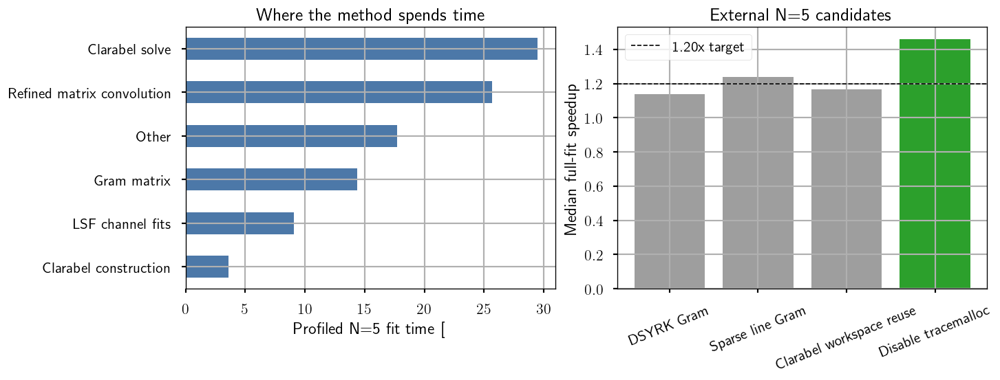

In [21]:
n5_profile = pd.Series(
    {
        "Clarabel solve": 29.5,
        "Refined matrix convolution": 25.7,
        "Gram matrix": 14.4,
        "LSF channel fits": 9.1,
        "Clarabel construction": 3.6,
        "Other": 17.7,
    },
    name="profile share [%]",
)

candidate_table = pd.DataFrame(
    [
        {
            "candidate": "DSYRK Gram",
            "baseline median [s]": 7.185,
            "candidate median [s]": 6.325,
            "speedup": 1.136,
            "max model delta": 7.53e-10,
            "decision": "reject: below 1.20x",
        },
        {
            "candidate": "Sparse line Gram",
            "baseline median [s]": 8.039,
            "candidate median [s]": 6.498,
            "speedup": 1.237,
            "max model delta": 2.16e-9,
            "decision": "diagnostic: confirmation not consistently faster",
        },
        {
            "candidate": "Clarabel workspace reuse",
            "baseline median [s]": 6.315,
            "candidate median [s]": 5.409,
            "speedup": 1.167,
            "max model delta": 3.96e-3,
            "decision": "reject: numerical drift",
        },
        {
            "candidate": "Disable tracemalloc",
            "baseline median [s]": 6.721,
            "candidate median [s]": 4.606,
            "speedup": 1.459,
            "max model delta": 0.0,
            "decision": "discuss: changes peak-memory reporting",
        },
    ]
)
display(candidate_table.style.format(precision=3))

figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
n5_profile.sort_values().plot.barh(ax=axes[0], color="#4c78a8")
axes[0].set(xlabel="Profiled N=5 fit time [%]", title="Where the method spends time")

colors = ["#9e9e9e", "#9e9e9e", "#9e9e9e", "#2ca02c"]
axes[1].bar(candidate_table["candidate"], candidate_table["speedup"], color=colors)
axes[1].axhline(1.20, color="black", linestyle="--", linewidth=1, label="1.20x target")
axes[1].set(ylabel="Median full-fit speedup", title="External N=5 candidates")
axes[1].tick_params(axis="x", rotation=22)
axes[1].legend()
plt.show()

## Refinement-cycle sensitivity screen

This controlled screen changes only `n_refinement_cycles` from 1 through 5.
Each value uses a fresh model and the same moderate-Moon input: native
12,401-pixel grid, `FLUX_SCI` row 837 scaled by $10^{14}$, unit inverse
variance, default PALACE, `lsf_sigma=0.5`, `moon_smooth_lambda=0.1`, and
`moon_interline_boost=0`. Each run includes its own final continuum and line
closure; intermediate stages from one five-cycle run are not substituted for
independent fits.

For this spectrum, two cycles are not an adequate replacement for four or
five. Relative to five cycles, the two-cycle final-model difference has an RMS
equal to 0.349 times the five-cycle residual RMS, the coefficient-vector
relative L2 difference is 18.0%, and the OH component relative L2 difference
is 11.9%. The maximum LSF FWHM differences reach 0.918 Angstrom in R and
0.964 Angstrom in Z. Two cycles reduce fit time by 37.8% relative to four, but
the skyline RMS is 6.8% higher and reduced chi-square is 13.8% higher.

The adjacent two-to-three-cycle change is still 0.241 residual RMS, with
a 12.8% coefficient-vector change. Four cycles are much closer to five:
the final-model difference is 0.040
times the five-cycle residual RMS and reduced chi-square differs by 0.33%.
This single-spectrum screen rejects two cycles. Together with the late-cycle
study below, it motivated the user-selected production default of five cycles;
it does not establish a global optimum.

In [22]:
cycle_counts = range(1, 6)
cycle_results = {}
cycle_surfaces = {}
cycle_masks = {}
cycle_timings = []
cycle_input = spectra[EXAMPLE_REGIME]

for cycles in cycle_counts:
    init_started = time.perf_counter()
    cycle_model = SkyDecompLSFSurfaceIterative(
        wave,
        base_dir=DEFAULT_BASE_DIR,
        config=LSFSurfaceIterativeConfig(n_refinement_cycles=cycles),
        **ITERATIVE_COMMON_KWARGS,
    )
    init_seconds = time.perf_counter() - init_started
    fit_started = time.perf_counter()
    cycle_result = cycle_model.fit(cycle_input["flux"], cycle_input["ivar"])
    fit_seconds = time.perf_counter() - fit_started

    cycle_results[cycles] = cycle_result
    cycle_surfaces[cycles] = evaluate_lsf_surface(cycle_result.lsf_state, wave)
    cycle_masks[cycles] = cycle_model.skyline_mask.copy()
    cycle_timings.append(
        {"cycles": cycles, "init_s": init_seconds, "fit_s": fit_seconds}
    )
    print(f"N={cycles}: fit={fit_seconds:.3f} s, chi2={cycle_result.reduced_chi2:.6f}")
    del cycle_model
    gc.collect()

N=1: fit=57.794 s, chi2=3.267056


N=2: fit=84.578 s, chi2=1.887627


N=3: fit=110.351 s, chi2=1.690481


N=4: fit=134.926 s, chi2=1.659134


N=5: fit=161.908 s, chi2=1.653623


In [23]:
def cycle_rms(values):
    return float(np.sqrt(np.mean(np.asarray(values, dtype=float) ** 2)))


reference = cycle_results[5]
reference_surface = cycle_surfaces[5]
reference_residual_rms = cycle_rms(cycle_input["flux"] - reference.bestfit_lsf)
cycle_records = []
for timing in cycle_timings:
    cycles = timing["cycles"]
    result = cycle_results[cycles]
    residual = cycle_input["flux"] - result.bestfit_lsf
    mask = cycle_masks[cycles]
    component_changes = {
        name: np.linalg.norm(result.components[name] - reference.components[name])
        / max(np.linalg.norm(reference.components[name]), 1.0e-30)
        for name in ("moon", "diffuse", "oh", "atom", "orc", "o2")
    }
    cycle_records.append(
        {
            **timing,
            "reduced_chi2": result.reduced_chi2,
            "line_free_rms": cycle_rms(residual[~mask]),
            "skyline_rms": cycle_rms(residual[mask]),
            "model_delta_over_resid_5": (
                cycle_rms(result.bestfit_lsf - reference.bestfit_lsf)
                / reference_residual_rms
            ),
            "coef_relative_l2_5": np.linalg.norm(result.coef - reference.coef)
            / max(np.linalg.norm(reference.coef), 1.0e-30),
            "lsf_surface_rms_5": cycle_rms(cycle_surfaces[cycles] - reference_surface),
            "largest_component": max(component_changes, key=component_changes.get),
            "largest_component_relative_l2_5": max(component_changes.values()),
        }
    )

cycle_screen_table = pd.DataFrame(cycle_records)
display(cycle_screen_table.style.format(precision=5))

lsf_records = []
for cycles in (2, 4):
    for channel, lower, upper in LSF_CHANNELS:
        channel_mask = np.ones(wave.size, dtype=bool)
        if lower is not None:
            channel_mask &= wave >= lower
        if upper is not None:
            channel_mask &= wave < upper
        center, sigma = kernel_moments(cycle_surfaces[cycles][channel_mask])
        ref_center, ref_sigma = kernel_moments(reference_surface[channel_mask])
        spacing = np.median(np.diff(wave[channel_mask]))
        lsf_records.append(
            {
                "cycles": cycles,
                "channel": channel,
                "max_centroid_delta_pix": np.max(np.abs(center - ref_center)),
                "max_fwhm_delta_A": 2.354820045 * spacing * np.max(np.abs(sigma - ref_sigma)),
                "knots_equal_N5": np.array_equal(
                    cycle_results[cycles].lsf_state.knot_vectors[channel],
                    reference.lsf_state.knot_vectors[channel],
                ),
            }
        )
display(pd.DataFrame(lsf_records).style.format(precision=5))

adjacent_records = []
for lower_cycles in range(1, 5):
    upper_cycles = lower_cycles + 1
    lower = cycle_results[lower_cycles]
    upper = cycle_results[upper_cycles]
    component_changes = {
        name: np.linalg.norm(lower.components[name] - upper.components[name])
        / max(np.linalg.norm(upper.components[name]), 1.0e-30)
        for name in ("moon", "diffuse", "oh", "atom", "orc", "o2")
    }
    adjacent_records.append(
        {
            "transition": f"{lower_cycles} -> {upper_cycles}",
            "model_delta_over_N5_residual": (
                cycle_rms(lower.bestfit_lsf - upper.bestfit_lsf)
                / reference_residual_rms
            ),
            "coef_relative_l2": np.linalg.norm(lower.coef - upper.coef)
            / max(np.linalg.norm(upper.coef), 1.0e-30),
            "lsf_surface_rms": cycle_rms(
                cycle_surfaces[lower_cycles] - cycle_surfaces[upper_cycles]
            ),
            "largest_component": max(component_changes, key=component_changes.get),
            "largest_component_relative_l2": max(component_changes.values()),
        }
    )
display(pd.DataFrame(adjacent_records).style.format(precision=5))

,cycles,init_s,fit_s,reduced_chi2,line_free_rms,skyline_rms,model_delta_over_resid_5,coef_relative_l2_5,lsf_surface_rms_5,largest_component,largest_component_relative_l2_5
0,1,13.16387,57.79406,3.26706,0.28988,2.26310,0.95938,0.51962,0.07068,orc,0.35534
1,2,12.87549,84.57793,1.88763,0.28977,1.71359,0.34871,0.18047,0.02105,oh,0.11858
2,3,13.82954,110.35110,1.69048,0.28974,1.61990,0.12738,0.06028,0.00702,oh,0.04333
3,4,13.88691,134.92576,1.65913,0.29018,1.60445,0.03964,0.01592,0.00201,oh,0.01350
4,5,13.80260,161.90757,1.65362,0.29045,1.60169,0.00000,0.00000,0.00000,moon,0.00000


,cycles,channel,max_centroid_delta_pix,max_fwhm_delta_A,knots_equal_N5
0,2,B,0.00014,0.00012,True
1,2,R,0.18234,0.91771,True
2,2,Z,0.11922,0.96361,True
3,4,B,0.00001,0.00000,True
4,4,R,0.05659,0.28575,True
5,4,Z,0.02460,0.08683,True


,transition,model_delta_over_N5_residual,coef_relative_l2,lsf_surface_rms,largest_component,largest_component_relative_l2
0,1 -> 2,0.74389,0.41384,0.06095,orc,0.26662
1,2 -> 3,0.24065,0.12788,0.01494,orc,0.08291
2,3 -> 4,0.09312,0.04527,0.00512,oh,0.03167
3,4 -> 5,0.03964,0.01592,0.00201,oh,0.01350


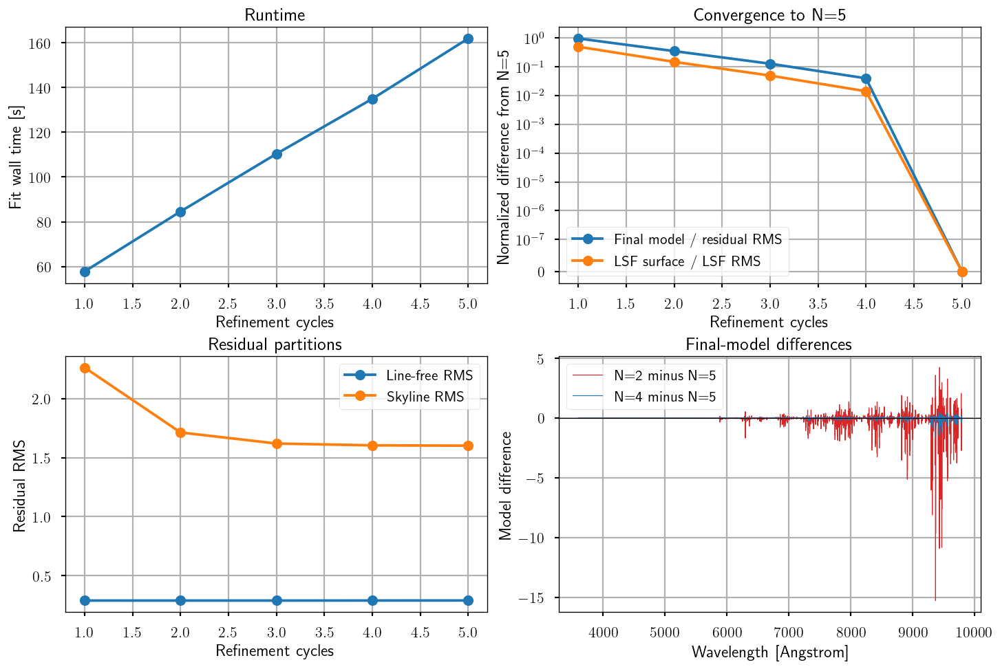

In [24]:
figure, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes[0, 0].plot(cycle_screen_table["cycles"], cycle_screen_table["fit_s"], marker="o")
axes[0, 0].set(xlabel="Refinement cycles", ylabel="Fit wall time [s]", title="Runtime")
axes[0, 1].plot(
    cycle_screen_table["cycles"],
    cycle_screen_table["model_delta_over_resid_5"],
    marker="o",
    label="Final model / residual RMS",
)
axes[0, 1].plot(
    cycle_screen_table["cycles"],
    cycle_screen_table["lsf_surface_rms_5"] / cycle_rms(reference_surface),
    marker="o",
    label="LSF surface / LSF RMS",
)
axes[0, 1].set_yscale("symlog", linthresh=1.0e-7)
axes[0, 1].set(xlabel="Refinement cycles", ylabel="Normalized difference from N=5", title="Convergence to N=5")
axes[0, 1].legend()
axes[1, 0].plot(cycle_screen_table["cycles"], cycle_screen_table["line_free_rms"], marker="o", label="Line-free RMS")
axes[1, 0].plot(cycle_screen_table["cycles"], cycle_screen_table["skyline_rms"], marker="o", label="Skyline RMS")
axes[1, 0].set(xlabel="Refinement cycles", ylabel="Residual RMS", title="Residual partitions")
axes[1, 0].legend()
for cycles, color in ((2, "#d62728"), (4, "#1f77b4")):
    axes[1, 1].plot(
        wave,
        cycle_results[cycles].bestfit_lsf - reference.bestfit_lsf,
        color=color,
        lw=0.7,
        label=f"N={cycles} minus N=5",
    )
axes[1, 1].axhline(0.0, color="black", lw=0.7)
axes[1, 1].set(xlabel="Wavelength [Angstrom]", ylabel="Model difference", title="Final-model differences")
axes[1, 1].legend()
plt.show()

## Late-cycle convergence and residuals

This extension repeats one internally consistent fresh-model series for
`n_refinement_cycles = 3, 4, 5, 6, 7, 8`. The input and every other fit
setting are identical to the preceding controlled screen. The saved
three-, four-, and five-cycle final models were reproduced bit for bit, but
their earlier timings are not mixed with this new series.

The result approaches a late-cycle plateau rather than improving indefinitely.
Reduced chi-square and skyline RMS reach their minima at six cycles; seven and
eight cycles move the fitted parameters further but very slightly worsen both
metrics. The adjacent final-model change drops from 0.093 times the N=8
residual RMS for `3 -> 4` to 0.0037 for `7 -> 8`. The corresponding coefficient
change drops from 4.53% to 0.17%.

The residual waterfall uses one common display offset and otherwise preserves
the raw residual amplitudes. The heatmap shows `residual(N) - residual(8)`;
its symmetric 99.5-percentile color limit is display-only. All metrics use the
full unclipped native arrays. `N=8` is an endpoint reference, not ground truth.
The user selected N=5 as the production default: it is near the plateau and
retains a lower runtime than the six-cycle metric minimum on this spectrum.

In [25]:
late_cycle_counts = range(3, 9)
late_cycle_results = {}
late_cycle_surfaces = {}
late_cycle_masks = {}
late_cycle_timings = []
late_cycle_input = spectra[EXAMPLE_REGIME]

for cycles in late_cycle_counts:
    init_started = time.perf_counter()
    late_model = SkyDecompLSFSurfaceIterative(
        wave,
        base_dir=DEFAULT_BASE_DIR,
        config=LSFSurfaceIterativeConfig(n_refinement_cycles=cycles),
        **ITERATIVE_COMMON_KWARGS,
    )
    init_seconds = time.perf_counter() - init_started
    fit_started = time.perf_counter()
    late_result = late_model.fit(
        late_cycle_input["flux"],
        late_cycle_input["ivar"],
    )
    fit_seconds = time.perf_counter() - fit_started

    late_cycle_results[cycles] = late_result
    late_cycle_surfaces[cycles] = evaluate_lsf_surface(late_result.lsf_state, wave)
    late_cycle_masks[cycles] = late_model.skyline_mask.copy()
    late_cycle_timings.append(
        {"cycles": cycles, "init_s": init_seconds, "fit_s": fit_seconds}
    )
    print(
        f"N={cycles}: fit={fit_seconds:.3f} s, "
        f"chi2={late_result.reduced_chi2:.7f}"
    )
    del late_model
    gc.collect()

N=3: fit=108.036 s, chi2=1.6904815


N=4: fit=135.939 s, chi2=1.6591343


N=5: fit=164.059 s, chi2=1.6536234


N=6: fit=185.668 s, chi2=1.6528474


N=7: fit=216.577 s, chi2=1.6528710


N=8: fit=239.196 s, chi2=1.6529886


In [26]:
def late_cycle_rms(values):
    return float(np.sqrt(np.mean(np.asarray(values, dtype=float) ** 2)))


late_reference = late_cycle_results[8]
late_reference_surface = late_cycle_surfaces[8]
late_reference_residual = late_cycle_input["flux"] - late_reference.bestfit_lsf
late_reference_residual_rms = late_cycle_rms(late_reference_residual)
late_reference_surface_rms = late_cycle_rms(late_reference_surface)
late_component_names = (
    "moon", "diffuse", "ho2", "feo", "o2ac", "oh", "atom", "orc", "o2"
)
late_summary_records = []
for timing in late_cycle_timings:
    cycles = timing["cycles"]
    result = late_cycle_results[cycles]
    residual = late_cycle_input["flux"] - result.bestfit_lsf
    mask = late_cycle_masks[cycles]
    component_changes = {
        name: np.linalg.norm(result.components[name] - late_reference.components[name])
        / max(np.linalg.norm(late_reference.components[name]), 1.0e-30)
        for name in late_component_names
    }
    largest = max(component_changes, key=component_changes.get)
    late_summary_records.append(
        {
            **timing,
            "reduced_chi2": result.reduced_chi2,
            "line_free_rms": late_cycle_rms(residual[~mask]),
            "skyline_rms": late_cycle_rms(residual[mask]),
            "model_delta_over_resid_8": (
                late_cycle_rms(result.bestfit_lsf - late_reference.bestfit_lsf)
                / late_reference_residual_rms
            ),
            "coef_relative_l2_8": np.linalg.norm(result.coef - late_reference.coef)
            / max(np.linalg.norm(late_reference.coef), 1.0e-30),
            "lsf_surface_relative_rms_8": (
                late_cycle_rms(late_cycle_surfaces[cycles] - late_reference_surface)
                / late_reference_surface_rms
            ),
            "largest_component": largest,
            "largest_component_relative_l2_8": component_changes[largest],
        }
    )
late_cycle_summary = pd.DataFrame(late_summary_records)
display(late_cycle_summary.style.format(precision=6))

late_adjacent_records = []
for lower_cycles in range(3, 8):
    upper_cycles = lower_cycles + 1
    lower = late_cycle_results[lower_cycles]
    upper = late_cycle_results[upper_cycles]
    component_changes = {
        name: np.linalg.norm(lower.components[name] - upper.components[name])
        / max(np.linalg.norm(upper.components[name]), 1.0e-30)
        for name in late_component_names
    }
    largest = max(component_changes, key=component_changes.get)
    late_adjacent_records.append(
        {
            "transition": f"{lower_cycles} -> {upper_cycles}",
            "model_delta_over_N8_residual": (
                late_cycle_rms(lower.bestfit_lsf - upper.bestfit_lsf)
                / late_reference_residual_rms
            ),
            "coef_relative_l2": np.linalg.norm(lower.coef - upper.coef)
            / max(np.linalg.norm(upper.coef), 1.0e-30),
            "lsf_surface_relative_rms": (
                late_cycle_rms(
                    late_cycle_surfaces[lower_cycles]
                    - late_cycle_surfaces[upper_cycles]
                )
                / late_reference_surface_rms
            ),
            "largest_component": largest,
            "largest_component_relative_l2": component_changes[largest],
        }
    )
late_cycle_adjacent = pd.DataFrame(late_adjacent_records)
display(late_cycle_adjacent.style.format(precision=6))

,cycles,init_s,fit_s,reduced_chi2,line_free_rms,skyline_rms,model_delta_over_resid_8,coef_relative_l2_8,lsf_surface_relative_rms_8,largest_component,largest_component_relative_l2_8
0,3,12.203606,108.036152,1.690481,0.289736,1.619900,0.150613,0.071034,0.058490,oh,0.051248
1,4,13.773913,135.938577,1.659134,0.290178,1.604448,0.066029,0.027421,0.023840,oh,0.022493
2,5,13.492146,164.059406,1.653623,0.290454,1.601693,0.027574,0.011737,0.010124,oh,0.009399
3,6,13.932238,185.668131,1.652847,0.290572,1.601295,0.011016,0.004860,0.004100,oh,0.003760
4,7,13.278851,216.576975,1.652871,0.290612,1.601302,0.003675,0.001661,0.001338,oh,0.001254
5,8,14.655336,239.196101,1.652989,0.290627,1.601359,0.000000,0.000000,0.000000,moon,0.000000


,transition,model_delta_over_N8_residual,coef_relative_l2,lsf_surface_relative_rms,largest_component,largest_component_relative_l2
0,3 -> 4,0.093139,0.045274,0.036068,oh,0.031673
1,4 -> 5,0.039643,0.015920,0.014151,oh,0.013498
2,5 -> 6,0.016780,0.006911,0.006082,oh,0.005716
3,6 -> 7,0.007504,0.003205,0.002774,oh,0.002561
4,7 -> 8,0.003675,0.001661,0.001338,oh,0.001254


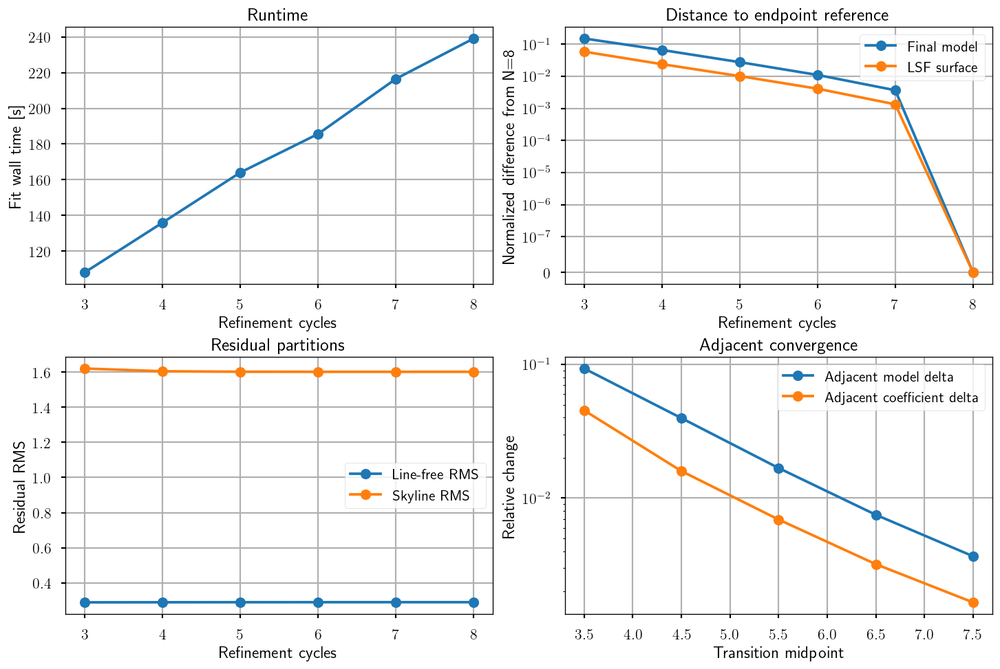

In [27]:
figure, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes[0, 0].plot(late_cycle_summary["cycles"], late_cycle_summary["fit_s"], marker="o")
axes[0, 0].set(xlabel="Refinement cycles", ylabel="Fit wall time [s]", title="Runtime")
axes[0, 1].plot(late_cycle_summary["cycles"], late_cycle_summary["model_delta_over_resid_8"], marker="o", label="Final model")
axes[0, 1].plot(late_cycle_summary["cycles"], late_cycle_summary["lsf_surface_relative_rms_8"], marker="o", label="LSF surface")
axes[0, 1].set_yscale("symlog", linthresh=1.0e-7)
axes[0, 1].set(xlabel="Refinement cycles", ylabel="Normalized difference from N=8", title="Distance to endpoint reference")
axes[0, 1].legend()
axes[1, 0].plot(late_cycle_summary["cycles"], late_cycle_summary["line_free_rms"], marker="o", label="Line-free RMS")
axes[1, 0].plot(late_cycle_summary["cycles"], late_cycle_summary["skyline_rms"], marker="o", label="Skyline RMS")
axes[1, 0].set(xlabel="Refinement cycles", ylabel="Residual RMS", title="Residual partitions")
axes[1, 0].legend()
transition_midpoints = np.arange(3, 8) + 0.5
axes[1, 1].plot(transition_midpoints, late_cycle_adjacent["model_delta_over_N8_residual"], marker="o", label="Adjacent model delta")
axes[1, 1].plot(transition_midpoints, late_cycle_adjacent["coef_relative_l2"], marker="o", label="Adjacent coefficient delta")
axes[1, 1].set_yscale("log")
axes[1, 1].set(xlabel="Transition midpoint", ylabel="Relative change", title="Adjacent convergence")
axes[1, 1].legend()
plt.show()

In [28]:
late_residuals = np.vstack(
    [late_cycle_input["flux"] - late_cycle_results[n].bestfit_lsf for n in late_cycle_counts]
)
late_residual_shift = 2.2 * np.percentile(np.abs(late_residuals), 99.5)
late_residual_offsets = np.arange(5, -1, -1) * late_residual_shift
late_colors = ["#440154", "#414487", "#2a788e", "#22a884", "#7ad151", "#fde725"]

late_waterfall = go.Figure()
for index, cycles in enumerate(late_cycle_counts):
    late_waterfall.add_trace(
        go.Scattergl(
            x=wave,
            y=late_residuals[index] + late_residual_offsets[index],
            mode="lines",
            name=f"N={cycles}",
            line={"color": late_colors[index], "width": 1.0},
            customdata=late_residuals[index],
            hovertemplate=(
                f"N={cycles}<br>wavelength=%{{x:.3f}} A"
                "<br>residual=%{customdata:.5g}<extra></extra>"
            ),
        )
    )
    late_waterfall.add_hline(
        y=late_residual_offsets[index],
        line_width=0.5,
        line_color="gray",
    )

late_presets = {
    "Full": [float(wave[0]), float(wave[-1])],
    "B": [float(wave[0]), 5784.0],
    "R": [5784.0, 7454.0],
    "Z": [7454.0, float(wave[-1])],
}
late_waterfall.update_layout(
    title="Final residual waterfall: cycles 3-8 (row 837, default PALACE)",
    xaxis_title="Wavelength [Angstrom]",
    yaxis_title=f"Residual + display offset ({late_residual_shift:.3g})",
    hovermode="closest",
    height=720,
    margin={"l": 75, "r": 30, "t": 100, "b": 60},
    updatemenus=[
        {
            "type": "buttons",
            "direction": "right",
            "x": 0.0,
            "y": 1.12,
            "buttons": [
                {
                    "label": label,
                    "method": "relayout",
                    "args": [{"xaxis.range": limits}],
                }
                for label, limits in late_presets.items()
            ],
        }
    ],
)
late_waterfall.show(config={"responsive": True, "displaylogo": False})

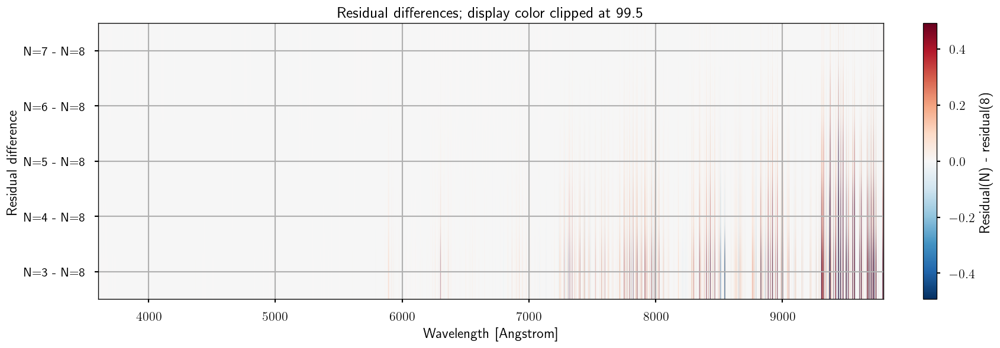

In [29]:
late_residual_difference = np.vstack(
    [late_residuals[n - 3] - late_residuals[-1] for n in range(3, 8)]
)
late_color_limit = np.percentile(np.abs(late_residual_difference), 99.5)
figure, axis = plt.subplots(figsize=(14, 4.8), constrained_layout=True)
image = axis.imshow(
    late_residual_difference,
    aspect="auto",
    origin="lower",
    extent=[wave[0], wave[-1], 2.5, 7.5],
    cmap="RdBu_r",
    vmin=-late_color_limit,
    vmax=late_color_limit,
)
axis.set_yticks(range(3, 8), [f"N={n} - N=8" for n in range(3, 8)])
axis.set(
    xlabel="Wavelength [Angstrom]",
    ylabel="Residual difference",
    title=(
        "Residual differences; display color clipped at "
        f"99.5% = {late_color_limit:.3g}"
    ),
)
figure.colorbar(image, ax=axis, label="Residual(N) - residual(8)")
plt.show()

## Reuse empirical per-fiber SolarBlue LSF reference FITS

The DRP 1.3.2 reference products use continuous M-spline densities, with 11 displacement components and four wavelength coefficients per channel. This notebook's historical comparison uses native-tap kernels and a median-stack input; an individual physical-fiber reference applies to a matching individual target spectrum through the SolarBlue decomposer. Select its physical fiber and actual camera calibration epoch from the target provenance. The existing comparison results above remain the historical experiment.

The [published reference methods and catalog](http://lumen.abudhabi.nyu.edu/sas/sdsswork/users/u6058164/lvm_lsf_epoch_coverage_drp132/lsf_calibration/) document the convex average, dispersion-derived scalar weights, Gaia flux ratio <0.1 selection, covariance factors and exact FITS schema. Both epoch and epoch–lunation references preserve calibration epochs; the survey-pooled file is a descriptive summary.

```python
from sky_decomp.lsf_reference import load_reference_lsf, reference_covariance
from sky_decomp.solar_lsf import SkyDecompPalaceCorrSolarBlueLSF

# Example of a stored reference; choose the target's fiber and camera epochs.
reference_file = Path('/data/sas/sdsswork/users/u6058164/lvm_lsf_epoch_coverage_drp132/lsf_calibration/epoch/lsf_60177.fits')
state = load_reference_lsf(reference_file, fiberid=123)
# For different camera epochs or sparse coverage, pass {'B': file_B, 'R': file_R, 'Z': file_Z}.
cov_B = reference_covariance(state.metrics['B']['reference_file'],
                            state.metrics['B']['reference_id'], kind='scatter')

# Apply to the separately loaded, matching individual DRP target spectrum.
# target_model_options contains that target's established assets/telluric settings.
target_model = SkyDecompPalaceCorrSolarBlueLSF(target_wave, **target_model_options)
target_result = target_model.fit(target_flux, target_ivar, fixed_lsf_state=state)
assert 'lsf_optimization_steps=0' in target_result.fit_summary
```

Loading copies the exact float64 coefficients; it performs no LSF fitting, centroid alignment or regridding. The fit checks native-grid identity and displacement support. Covariance matrices are channel-specific. `kind='scatter'` describes exposure-to-exposure spread; `kind='conditional_mean'` gives a fixed-weight night-cluster estimate, whose interpretation differs from prediction error. A single exposure has undefined scatter and a single night has undefined conditional mean error. Independent transfer validation is needed to quantify calibration precision.
